# INTI-3K v8 · Notebook Reproducible Oficial (`submission_notebook.ipynb`)

**Hackathon IA PUCP 2026 (DSC PUCP × IA-PUCP) · Equipo PASSWORD**

Este notebook **100% autocontenido** reproduce de principio a fin nuestro modelo único unificado **`EnsembleV8`** (**Full DirectRes** sobre 4 arquitecturas complementarias guiadas por física andina + *TemporalLagMixer* + *Cross-Attention* GFS→WRF) utilizando **exclusivamente la data oficial** (`train.npz`, `test.npz`, `static.npz`):

1. **Ingeniería Física y Atención Temporal v8 (`98` canales GFS + `10` DEM):**
   - Ventanas temporales extendidas con ciclo diurno `±24h`: `V7_LAGS = (-24, -6, -3, -1, 0, 1, 3, 6, 24)`.
   - **`TemporalLagMixer`**: atención temporal multi-cabeza (`MultiheadAttention`) por celda GFS sobre los 9 lags `[-24..+24]`.
   - Régimen sinóptico 24h (`M24`, `S24`) y **gradientes espaciales GFS (`17×13`)**: $\nabla T$, $\nabla RH$, **Divergencia** ($\partial_x U + \partial_y V$) y **Vorticidad** ($\partial_x V - \partial_y U$).
   - **Ancla Física Directa (`DirectPhysicalAnchor`) en TODOS los miembros**: elimina la deriva húmeda feb–abr sumando al GFS interpolado gradientes altitudinales aprendibles por hora UTC (`lapse_rate_h` en K/km y `rh_elev_h` en %/km) + sesgo diurno 3 km + prior adiabático seguro `rh_prior_norm`.
2. **4 Arquitecturas Complementarias *Full DirectRes* (`EnsembleV8`):**
   - `DirectResConvNeXtV8` (`w=84`, kernels `7×7` dilatados + *Cross-Attention*)
   - `DirectResMultiScaleV8` (`w=96`, bloques paralelos `3×3 + 7×7` dilatados + *Cross-Attention*)
   - `DirectResUNetV8` (`w=64`, U-Net 3 niveles + *Cross-Attention* en `18×9`)
   - `DirectResFNOV8` (`w=32`, FNO compacto regularizado `modes 12×8` + *Cross-Attention*)
3. **Protocolo en 2 Fases (Rigor + Máximo Desempeño en Julio–Agosto):**
   - **Fase A (Validación Temporal `val = ttr >= '2024061600'`):** Mide el Skill Score real (`~0.407+`), calibra `blend_weights` en el simplex (`paso=0.05`) e inspecciona los lapse-rates aprendidos.
   - **Fase B (Refit Final 100% Data Oficial · `2,935` horas Feb 18 – Jun 30):** Reentrena las 4 familias con las épocas óptimas validadas acotadas a `[14, 22]` usando EMA (`decay=0.992`).
4. **Exportación Limpia:** Guarda `models/modelo.pt` (`state_dict`), `models/norm_stats.npz` (`arch="ensemble_v8"`) y `submission.csv` (`646,800` filas verificadas).


In [1]:
import copy
import gc
import glob
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

DEFAULT_SEED = 42

def seed_everything(seed: int = DEFAULT_SEED) -> int:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    return seed

seed_everything(DEFAULT_SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo activo: {device.upper()} | PyTorch: {torch.__version__}")

def find(name: str) -> str:
    hits = (
        glob.glob(f"/kaggle/input/**/{name}", recursive=True)
        + glob.glob(f"../data/**/{name}", recursive=True)
        + glob.glob(f"data/**/{name}", recursive=True)
        + glob.glob(f"**/{name}", recursive=True)
    )
    assert hits, f"No encuentro {name}. Descarga la data oficial en data/."
    return hits[0]

ROOT_DIR = Path("..").resolve() if (Path("../data").is_dir() or Path("../models").is_dir()) else Path(".").resolve()
MODELS_DIR = ROOT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

tr = np.load(find("train.npz"))
te = np.load(find("test.npz"))
st = dict(np.load(find("static.npz")))

Xtr, Ytr, ttr = tr["X"], tr["Y"], tr["times"].astype(str)
Xte, tte = te["X"], te["times"].astype(str)
dem = st["dem"].astype(np.float32)

VARS = ["RH", "T", "U", "V"]
print(f"Train X: {Xtr.shape} | Y: {Ytr.shape} | Rango: {ttr[0]} -> {ttr[-1]}")
print(f"Test  X: {Xte.shape} | Rango: {tte[0]} -> {tte[-1]}")
print(f"DEM: {dem.shape} | Elevación: {dem.min():.0f} m - {dem.max():.0f} m")


Dispositivo activo: CUDA | PyTorch: 2.14.1+cu126


Train X: (2935, 17, 13, 4) | Y: (2935, 70, 35, 4) | Rango: 2024021800 -> 2024063023
Test  X: (792, 17, 13, 4) | Rango: 2024070200 -> 2024080423
DEM: (70, 35) | Elevación: 115 m - 5782 m


In [2]:
def extract_hour_utc(t: np.ndarray) -> np.ndarray:
    return np.array([int(str(k)[-2:]) for k in t], dtype=np.int64)

def compute_climatology(Y: np.ndarray, t: np.ndarray) -> np.ndarray:
    h = extract_hour_utc(t)
    return np.stack([Y[h == k].mean(0) for k in range(24)]).astype(np.float32)

val_mask = ttr >= "2024061600"
trn_mask = ~val_mask
full_mask = np.ones(len(ttr), dtype=bool)

h_tr = extract_hour_utc(ttr)
h_te = extract_hour_utc(tte)

clim_trn = compute_climatology(Ytr[trn_mask], ttr[trn_mask])
clim_rmse_val = np.sqrt(((clim_trn[h_tr[val_mask]] - Ytr[val_mask]) ** 2).mean(axis=(0, 1, 2)))

def evaluate_skill_score(pred: np.ndarray, true: np.ndarray, ref_clim_rmse: np.ndarray = clim_rmse_val):
    rmse = np.sqrt(((pred - true) ** 2).mean(axis=(0, 1, 2)))
    rel_skill = 1.0 - (rmse / ref_clim_rmse)
    total_skill = float(rel_skill.mean())
    rmse_dict = {k: round(float(v), 4) for k, v in zip(VARS, rmse)}
    skill_dict = {k: round(float(v), 4) for k, v in zip(VARS, rel_skill)}
    return total_skill, rmse_dict, skill_dict

base_sc, base_rmse, _ = evaluate_skill_score(clim_trn[h_tr[val_mask]], Ytr[val_mask])
print(f"Split Temporal -> Train: {trn_mask.sum()} h | Val (16-30 jun): {val_mask.sum()} h | Full: {full_mask.sum()} h")
print(f"Baseline Climatología -> Skill Score: {base_sc:.4f} | RMSE: {base_rmse}")


Split Temporal -> Train: 2599 h | Val (16-30 jun): 336 h | Full: 2935 h
Baseline Climatología -> Skill Score: 0.0000 | RMSE: {'RH': 17.1766, 'T': 2.0097, 'U': 2.2607, 'V': 1.9455}


In [3]:
V7_LAGS = (-24, -6, -3, -1, 0, 1, 3, 6, 24)

def smooth_2d(a: np.ndarray, k: int = 9) -> np.ndarray:
    p = k // 2
    ap = np.pad(a, p, mode="edge")
    out = np.zeros_like(a, dtype=np.float32)
    for di in range(k):
        for dj in range(k):
            out += ap[di : di + a.shape[0], dj : dj + a.shape[1]]
    return out / (k * k)

def build_topographic_features(dem_arr: np.ndarray, wrf_lats: np.ndarray, wrf_lons: np.ndarray) -> np.ndarray:
    dem_f = dem_arr.astype(np.float32)
    dem_norm = (dem_f - dem_f.mean()) / (dem_f.std() + 1e-6)
    dy, dx = np.gradient(dem_f)
    dx_norm = (dx - dx.mean()) / (dx.std() + 1e-6)
    dy_norm = (dy - dy.mean()) / (dy.std() + 1e-6)
    slope = np.sqrt(dx**2 + dy**2)
    slope_norm = (slope - slope.mean()) / (slope.std() + 1e-6)
    aspect = np.arctan2(dy, dx)
    sin_aspect = np.sin(aspect).astype(np.float32)
    cos_aspect = np.cos(aspect).astype(np.float32)
    tpi_local = dem_f - smooth_2d(dem_f, k=3)
    tpi_local_norm = (tpi_local - tpi_local.mean()) / (tpi_local.std() + 1e-6)
    tpi_meso = dem_f - smooth_2d(dem_f, k=9)
    tpi_meso_norm = (tpi_meso - tpi_meso.mean()) / (tpi_meso.std() + 1e-6)
    LAT, LON = np.meshgrid(wrf_lats, wrf_lons, indexing="ij")
    lat_norm = ((LAT - LAT.mean()) / (LAT.std() + 1e-6)).astype(np.float32)
    lon_norm = ((LON - LON.mean()) / (LON.std() + 1e-6)).astype(np.float32)
    return np.stack([
        dem_norm, dy_norm, dx_norm, slope_norm,
        sin_aspect, cos_aspect, tpi_local_norm, tpi_meso_norm,
        lat_norm, lon_norm,
    ], axis=0).astype(np.float32)

def build_sampling_grid(st_dict, dev: str) -> torch.Tensor:
    glat, glon = st_dict["gfs_lats"], st_dict["gfs_lons"]
    wlat, wlon = st_dict["wrf_lats"], st_dict["wrf_lons"]
    LAT, LON = np.meshgrid(wlat, wlon, indexing="ij")
    gy = (LAT - glat[0]) / (glat[-1] - glat[0]) * 2 - 1
    gx = (LON - glon[0]) / (glon[-1] - glon[0]) * 2 - 1
    grid = np.stack([gx, gy], axis=-1)[None].astype(np.float32)
    return torch.tensor(grid, dtype=torch.float32, device=dev)

def compute_dewpoint_c(T_k: np.ndarray, RH_pct: np.ndarray) -> np.ndarray:
    T_c = T_k - 273.15
    rh = np.clip(RH_pct, 1.0, 100.0) / 100.0
    a, b = 17.625, 243.04
    gamma = np.log(rh) + (a * T_c) / (b + T_c)
    return ((b * gamma) / (a - gamma)).astype(np.float32)

def build_v7_temporal_and_spatial_features(X: np.ndarray, t: np.ndarray):
    ts = pd.to_datetime(t.astype(str), format="%Y%m%d%H")
    ts_ns = ts.values.astype("datetime64[h]").astype(np.int64)
    pos = {int(h): i for i, h in enumerate(ts_ns)}
    N = len(X)
    W = np.empty((N, len(V7_LAGS)) + X.shape[1:], dtype=np.float32)
    M24 = np.empty_like(X, dtype=np.float32)
    S24 = np.empty_like(X, dtype=np.float32)
    for i, cur_h in enumerate(ts_ns):
        for j, lag in enumerate(V7_LAGS):
            target_h = int(cur_h + lag)
            idx = pos.get(target_h, None)
            if idx is None:
                for delta in (1, -1, 2, -2, 3, -3):
                    idx = pos.get(target_h + delta, None)
                    if idx is not None:
                        break
            W[i, j] = X[idx] if idx is not None else X[i]
        win_idxs = [pos[int(cur_h + d)] for d in range(-12, 13) if int(cur_h + d) in pos]
        if len(win_idxs) >= 2:
            sub = X[win_idxs]
            M24[i] = sub.mean(axis=0)
            S24[i] = sub.std(axis=0)
        else:
            M24[i] = X[i]
            S24[i] = 0.0

    rh, temp, u, v = X[..., 0], X[..., 1], X[..., 2], X[..., 3]
    dRH_row, dRH_dx = np.gradient(rh, axis=(1, 2))
    dT_row, dT_dx = np.gradient(temp, axis=(1, 2))
    dU_row, dU_dx = np.gradient(u, axis=(1, 2))
    dV_row, dV_dx = np.gradient(v, axis=(1, 2))
    div = dU_dx + (-dV_row)
    vort = dV_dx - (-dU_row)
    GRAD = np.stack([dT_dx, -dT_row, dRH_dx, -dRH_row, div, vort], axis=1).astype(np.float32)
    TD = compute_dewpoint_c(temp, rh)[:, None, :, :].astype(np.float32)
    return W, M24, S24, GRAD, TD

t0 = time.time()
W_tr, M24_tr, S24_tr, GRAD_tr, TD_tr = build_v7_temporal_and_spatial_features(Xtr, ttr)
W_te, M24_te, S24_te, GRAD_te, TD_te = build_v7_temporal_and_spatial_features(Xte, tte)

grid_t = build_sampling_grid(st, device)
topo_np = build_topographic_features(dem, st["wrf_lats"], st["wrf_lons"])
topo_t = torch.tensor(topo_np, dtype=torch.float32, device=device)
dem_smooth = smooth_2d(dem, k=9)
lapse_phys = (-0.0065 * (dem - dem_smooth)).astype(np.float32)
dem_delta_km_np = ((dem - dem_smooth) / 1000.0).astype(np.float32)
dem_delta_km_t = torch.tensor(dem_delta_km_np, dtype=torch.float32, device=device)

months_tr = pd.to_datetime(ttr, format="%Y%m%d%H").month.values
month_w_map = {2: 0.50, 3: 0.80, 4: 0.90, 5: 1.15, 6: 1.45}
raw_month_w = np.array([month_w_map.get(int(m), 1.0) for m in months_tr], dtype=np.float32)

def compute_norm_context(fit_mask: np.ndarray):
    clim = compute_climatology(Ytr[fit_mask], ttr[fit_mask])
    clim_rmse = np.sqrt(((clim[h_tr[fit_mask]] - Ytr[fit_mask]) ** 2).mean(axis=(0, 1, 2))).astype(np.float32)
    mu_x = Xtr[fit_mask].mean(axis=(0, 1, 2)).astype(np.float32)
    sd_x = Xtr[fit_mask].std(axis=(0, 1, 2)).astype(np.float32)
    mu_td = float(TD_tr[fit_mask].mean())
    sd_td = float(TD_tr[fit_mask].std() + 1e-6)
    mu_grad = GRAD_tr[fit_mask].mean(axis=(0, 2, 3), keepdims=True).astype(np.float32)
    sd_grad = (GRAD_tr[fit_mask].std(axis=(0, 2, 3), keepdims=True) + 1e-6).astype(np.float32)
    anom_sd = (Ytr[fit_mask] - clim[h_tr[fit_mask]]).std(axis=(0, 1, 2)).astype(np.float32)
    sw = raw_month_w.copy()
    sw[fit_mask] /= sw[fit_mask].mean()
    return {
        "clim": clim,
        "clim_rmse": clim_rmse,
        "mu_x": mu_x,
        "sd_x": sd_x,
        "mu_td": mu_td,
        "sd_td": sd_td,
        "mu_grad": mu_grad,
        "sd_grad": sd_grad,
        "anom_sd": anom_sd,
        "sw": sw,
        "Wn": ((W_tr - mu_x) / sd_x).astype(np.float32),
        "Mn": ((M24_tr - mu_x) / sd_x).astype(np.float32),
        "Sn": (S24_tr / sd_x).astype(np.float32),
        "Gn": ((GRAD_tr - mu_grad) / sd_grad).astype(np.float32),
        "Tn": ((TD_tr - mu_td) / sd_td).astype(np.float32),
        "lapse_delta_norm": torch.tensor(lapse_phys / float(sd_x[1]), dtype=torch.float32, device=device),
        "clim_t": torch.tensor(clim, dtype=torch.float32, device=device),
        "clim_rmse_t": torch.tensor(clim_rmse, dtype=torch.float32, device=device),
        "anom_sd_t": torch.tensor(anom_sd, dtype=torch.float32, device=device),
        "mu_x_t": torch.tensor(mu_x, dtype=torch.float32, device=device),
        "sd_x_t": torch.tensor(sd_x, dtype=torch.float32, device=device),
    }

print(f"Features v8 construidos en {time.time()-t0:.1f}s | W_tr: {W_tr.shape} | GRAD_tr: {GRAD_tr.shape}")


Features v8 construidos en 1.3s | W_tr: (2935, 9, 17, 13, 4) | GRAD_tr: (2935, 6, 17, 13)


In [4]:
class SEBlock(nn.Module):
    def __init__(self, channels: int, reduction: int = 4):
        super().__init__()
        mid = max(channels // reduction, 8)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(channels, mid), nn.GELU(),
            nn.Linear(mid, channels), nn.Sigmoid(),
        )
    def forward(self, x):
        return x * self.fc(x).unsqueeze(-1).unsqueeze(-1)

class TemporalLagMixer(nn.Module):
    def __init__(self, d_t: int = 24, num_heads: int = 4, dropout: float = 0.05):
        super().__init__()
        self.in_proj = nn.Linear(4, d_t)
        self.lag_pos = nn.Parameter(0.02 * torch.randn(1, 9, d_t))
        self.attn = nn.MultiheadAttention(embed_dim=d_t, num_heads=num_heads, dropout=dropout, batch_first=True)
        self.norm = nn.LayerNorm(d_t)
        self.out_proj = nn.Sequential(nn.Linear(d_t * 2, d_t), nn.GELU())

    def forward(self, w_norm: torch.Tensor) -> torch.Tensor:
        B, L, H, W, C = w_norm.shape
        tokens = w_norm.permute(0, 2, 3, 1, 4).reshape(B * H * W, L, C)
        x = self.in_proj(tokens) + self.lag_pos
        attn_out, _ = self.attn(x, x, x, need_weights=False)
        x = self.norm(x + attn_out)
        pooled = torch.cat([x[:, 4], x.mean(dim=1)], dim=-1)
        return self.out_proj(pooled).reshape(B, H, W, -1).permute(0, 3, 1, 2)

class DirectPhysicalAnchor(nn.Module):
    def __init__(self, grid, dem_delta_km, mu_x, sd_x, anom_sd):
        super().__init__()
        self.register_buffer("grid", grid)
        self.register_buffer("dem_delta_km", dem_delta_km[None, :, :, None])
        self.register_buffer("mu_x", mu_x)
        self.register_buffer("sd_x", sd_x)
        self.register_buffer("anom_sd", anom_sd)
        self.lapse_rate_h = nn.Parameter(torch.full((24, 1, 1, 1), -5.0))
        self.rh_elev_h = nn.Parameter(torch.zeros(24, 1, 1, 1))
        self.diurnal_bias = nn.Parameter(torch.zeros(24, 70, 35, 4))

    def forward(self, xt, h, res):
        B = xt.shape[0]
        xt_phys = xt * self.sd_x + self.mu_x
        anchor = F.grid_sample(
            xt_phys.permute(0, 3, 1, 2),
            self.grid.expand(B, -1, -1, -1),
            mode="bilinear", align_corners=True,
        ).permute(0, 2, 3, 1)
        rh_anchor = anchor[..., 0:1] + self.rh_elev_h[h] * self.dem_delta_km
        t_anchor = anchor[..., 1:2] + self.lapse_rate_h[h] * self.dem_delta_km
        anchor_adj = torch.cat([rh_anchor, t_anchor, anchor[..., 2:4]], dim=-1)
        return anchor_adj + self.diurnal_bias[h] + res * self.anom_sd

class GFS2WRFCrossAttention(nn.Module):
    def __init__(self, high_ch: int, gfs_ch: int, d_attn: int = 64, num_heads: int = 4):
        super().__init__()
        self.q_proj = nn.Conv2d(high_ch, d_attn, kernel_size=1)
        self.kv_proj = nn.Conv2d(gfs_ch, d_attn, kernel_size=1)
        self.q_pos = nn.Parameter(0.02 * torch.randn(1, 18 * 9, d_attn))
        self.k_pos = nn.Parameter(0.02 * torch.randn(1, 17 * 13, d_attn))
        self.attn = nn.MultiheadAttention(embed_dim=d_attn, num_heads=num_heads, dropout=0.05, batch_first=True)
        self.norm = nn.LayerNorm(d_attn)
        self.out_proj = nn.Conv2d(d_attn, high_ch, kernel_size=1)
        self.alpha = nn.Parameter(torch.tensor(0.10))

    def forward(self, feat_high, feat_gfs):
        B, _, H, W = feat_high.shape
        q_seq = F.adaptive_avg_pool2d(self.q_proj(feat_high), (18, 9)).flatten(2).transpose(1, 2) + self.q_pos
        k_seq = self.kv_proj(feat_gfs).flatten(2).transpose(1, 2) + self.k_pos
        attn_out, _ = self.attn(q_seq, k_seq, k_seq, need_weights=False)
        attn_map = self.norm(q_seq + attn_out).transpose(1, 2).reshape(B, -1, 18, 9)
        attn_up = F.interpolate(attn_map, size=(H, W), mode="bilinear", align_corners=True)
        return feat_high + self.alpha * self.out_proj(attn_up)

def _assemble_v7_gfs_tensor(w_norm, m24_norm, s24_norm, grad_norm, td_norm, h):
    B = w_norm.shape[0]
    xt, xm3, xp3, xm24 = w_norm[:, 4], w_norm[:, 2], w_norm[:, 6], w_norm[:, 0]
    wspd = torch.stack([
        torch.sqrt(w_norm[:, idx, :, :, 2]**2 + w_norm[:, idx, :, :, 3]**2 + 1e-6)
        for idx in (0, 2, 4, 6, 8)
    ], dim=1)
    d_prev = (xt - xm3).permute(0, 3, 1, 2)
    d_next = (xp3 - xt).permute(0, 3, 1, 2)
    d_diurnal = (xt - m24_norm).permute(0, 3, 1, 2)
    d_24h = (xt - xm24).permute(0, 3, 1, 2)
    w_flat = w_norm.permute(0, 1, 4, 2, 3).reshape(B, 36, 17, 13)
    m24_flat = m24_norm.permute(0, 3, 1, 2)
    s24_flat = s24_norm.permute(0, 3, 1, 2)
    ang = 2.0 * np.pi * h / 24.0
    h_vec = torch.stack([torch.sin(ang), torch.cos(ang)], dim=1)
    hh_low = h_vec[..., None, None].expand(B, 2, 17, 13)
    gfs_in = torch.cat([w_flat, m24_flat, s24_flat, grad_norm, td_norm, wspd, d_prev, d_next, d_diurnal, d_24h, hh_low], dim=1)
    return gfs_in, xt, h_vec

def _fuse_highres_v8(f_low, xt, m24_norm, s24_norm, grad_norm, td_norm, h_vec, grid, topo, lapse_delta, dem_delta_km, mu_x, sd_x, learned_static):
    B = xt.shape[0]
    grid_b = grid.expand(B, -1, -1, -1)
    f_up = F.grid_sample(f_low, grid_b, mode="bilinear", align_corners=True)
    raw_cat = torch.cat([xt.permute(0, 3, 1, 2), m24_norm.permute(0, 3, 1, 2), s24_norm.permute(0, 3, 1, 2), grad_norm, td_norm], dim=1)
    raw_up = F.grid_sample(raw_cat, grid_b, mode="bilinear", align_corners=True)
    topo_b = topo.expand(B, -1, -1, -1)
    u_up, v_up = raw_up[:, 2:3], raw_up[:, 3:4]
    dy_n, dx_n = topo_b[:, 1:2], topo_b[:, 2:3]
    oro_feats = torch.cat([u_up * dx_n + v_up * dy_n, u_up * dy_n - v_up * dx_n], dim=1)
    t_prior = raw_up[:, 1:2] + lapse_delta.expand(B, -1, -1, -1)

    rh_up_phys = torch.clamp(raw_up[:, 0:1] * sd_x[0] + mu_x[0], 1.0, 100.0)
    t_up_c = torch.clamp((raw_up[:, 1:2] * sd_x[1] + mu_x[1]) - 273.15, -50.0, 50.0)
    a_mag, b_mag = 17.625, 243.04
    gamma = torch.log(rh_up_phys / 100.0) + (a_mag * t_up_c) / (b_mag + t_up_c)
    td_up_c = torch.clamp((b_mag * gamma) / (a_mag - gamma), -60.0, 40.0)
    dkm_b = dem_delta_km[None, None].expand(B, -1, -1, -1)
    t_adj_c = torch.clamp(t_up_c - 6.5 * dkm_b, -50.0, 50.0)
    td_adj_c = torch.clamp(td_up_c - 1.5 * dkm_b, -60.0, 40.0)
    es_t = torch.exp((a_mag * t_adj_c) / (b_mag + t_adj_c))
    es_td = torch.exp((a_mag * td_adj_c) / (b_mag + td_adj_c))
    rh_prior = torch.clamp(100.0 * es_td / (es_t + 1e-6), 1.0, 100.0)
    rh_prior_norm = (rh_prior - mu_x[0]) / sd_x[0]

    static_b = learned_static.expand(B, -1, -1, -1)
    hh_high = h_vec[..., None, None].expand(B, 2, 70, 35)
    fused = torch.cat([f_up, raw_up, t_prior, rh_prior_norm, oro_feats, topo_b, static_b, hh_high], dim=1)
    return fused, topo_b, oro_feats

class ConvNeXtBlock2D(nn.Module):
    def __init__(self, dim: int, kernel_size: int = 7, dilation: int = 1, expand: int = 3, dropout: float = 0.14):
        super().__init__()
        padding = (kernel_size - 1) * dilation // 2
        self.dwconv = nn.Conv2d(dim, dim, kernel_size, padding=padding, dilation=dilation, groups=dim)
        self.norm = nn.GroupNorm(1, dim)
        self.pw1 = nn.Conv2d(dim, dim * expand, 1)
        self.act = nn.GELU()
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()
        self.pw2 = nn.Conv2d(dim * expand, dim, 1)
        self.gamma = nn.Parameter(1e-3 * torch.ones(1, dim, 1, 1))
    def forward(self, x):
        return x + self.gamma * self.pw2(self.drop(self.act(self.pw1(self.norm(self.dwconv(x))))))

class MultiScaleBlock2D(nn.Module):
    def __init__(self, dim: int, dilation: int = 2, expand: int = 3, dropout: float = 0.18):
        super().__init__()
        pad7 = (7 - 1) * dilation // 2
        self.dw3 = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim)
        self.dw7 = nn.Conv2d(dim, dim, kernel_size=7, padding=pad7, dilation=dilation, groups=dim)
        self.mix = nn.Conv2d(dim * 2, dim, kernel_size=1)
        self.norm = nn.GroupNorm(1, dim)
        self.pw1 = nn.Conv2d(dim, dim * expand, kernel_size=1)
        self.act = nn.GELU()
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()
        self.pw2 = nn.Conv2d(dim * expand, dim, kernel_size=1)
        self.gamma = nn.Parameter(1e-3 * torch.ones(1, dim, 1, 1))
    def forward(self, x):
        ms = self.mix(torch.cat([self.dw3(x), self.dw7(x)], dim=1))
        return x + self.gamma * self.pw2(self.drop(self.act(self.pw1(self.norm(ms)))))

class CompactResBlock(nn.Module):
    def __init__(self, channels: int, dropout: float = 0.12):
        super().__init__()
        groups = 8 if channels % 8 == 0 else 4
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False), nn.GroupNorm(groups, channels), nn.GELU(),
            nn.Dropout2d(dropout) if dropout > 0 else nn.Identity(),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False), nn.GroupNorm(groups, channels),
        )
        self.se = SEBlock(channels)
        self.act = nn.GELU()
    def forward(self, x):
        return self.act(x + self.se(self.block(x)))

class SpectralConv2d(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, modes1: int = 12, modes2: int = 8):
        super().__init__()
        self.out_channels, self.modes1, self.modes2 = out_channels, modes1, modes2
        scale = 1.0 / (in_channels * out_channels)
        self.w1_r = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes1, modes2))
        self.w1_i = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes1, modes2))
        self.w2_r = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes1, modes2))
        self.w2_i = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes1, modes2))
    @staticmethod
    def _compl_mul2d(xr, xi, wr, wi):
        return torch.complex(
            torch.einsum("bixy,ioxy->boxy", xr, wr) - torch.einsum("bixy,ioxy->boxy", xi, wi),
            torch.einsum("bixy,ioxy->boxy", xr, wi) + torch.einsum("bixy,ioxy->boxy", xi, wr),
        )
    def forward(self, x):
        B, _, H, W = x.shape
        x_ft = torch.fft.rfft2(x, norm="ortho")
        out_ft = torch.zeros(B, self.out_channels, H, W // 2 + 1, dtype=torch.cfloat, device=x.device)
        m1, m2 = min(self.modes1, H // 2), min(self.modes2, W // 2 + 1)
        x1, x2 = x_ft[:, :, :m1, :m2], x_ft[:, :, -m1:, :m2]
        out_ft[:, :, :m1, :m2] = self._compl_mul2d(x1.real, x1.imag, self.w1_r[:, :, :m1, :m2], self.w1_i[:, :, :m1, :m2])
        out_ft[:, :, -m1:, :m2] = self._compl_mul2d(x2.real, x2.imag, self.w2_r[:, :, :m1, :m2], self.w2_i[:, :, :m1, :m2])
        return torch.fft.irfft2(out_ft, s=(H, W), norm="ortho")

class FNOBlock2D(nn.Module):
    def __init__(self, dim: int, modes1: int = 12, modes2: int = 8, dropout: float = 0.18):
        super().__init__()
        self.spectral = SpectralConv2d(dim, dim, modes1=modes1, modes2=modes2)
        self.local_conv = nn.Conv2d(dim, dim, 3, padding=1, groups=dim)
        self.pw = nn.Conv2d(dim, dim, 1)
        self.norm = nn.GroupNorm(8, dim)
        self.act = nn.GELU()
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()
    def forward(self, x):
        return x + self.drop(self.act(self.norm(self.spectral(x) + self.pw(self.local_conv(x)))))

class _DirectResBaseV8(nn.Module):
    def __init__(self, grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, dropout=0.15):
        super().__init__()
        self.register_buffer("topo", topo_features[None])
        self.register_buffer("lapse_delta", lapse_delta_norm[None, None])
        self.register_buffer("dem_delta_km_2d", dem_delta_km)
        self.temporal_mixer = TemporalLagMixer(d_t=24, num_heads=4, dropout=min(dropout, 0.08))
        self.learned_static = nn.Parameter(torch.zeros(1, 12, 70, 35))
        nn.init.normal_(self.learned_static, mean=0.0, std=0.01)
        self.anchor = DirectPhysicalAnchor(grid, dem_delta_km, mu_x, sd_x, anom_sd)

    def _encode_inputs(self, w_norm, m24_norm, s24_norm, grad_norm, td_norm, h):
        gfs_in, xt, h_vec = _assemble_v7_gfs_tensor(w_norm, m24_norm, s24_norm, grad_norm, td_norm, h.float())
        return torch.cat([gfs_in, self.temporal_mixer(w_norm)], dim=1), xt, h_vec

    def _fuse(self, f_low, xt, m24_norm, s24_norm, grad_norm, td_norm, h_vec):
        return _fuse_highres_v8(
            f_low, xt, m24_norm, s24_norm, grad_norm, td_norm, h_vec,
            self.anchor.grid, self.topo, self.lapse_delta, self.dem_delta_km_2d,
            self.anchor.mu_x, self.anchor.sd_x, self.learned_static,
        )

class DirectResConvNeXtV8(_DirectResBaseV8):
    def __init__(self, grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, w=84, dropout=0.15):
        super().__init__(grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, dropout)
        self.gfs_stem = nn.Sequential(
            nn.Conv2d(98, w, 3, padding=1), nn.GroupNorm(1, w), nn.GELU(),
            ConvNeXtBlock2D(w, 5, 1, 2, dropout * 0.5), ConvNeXtBlock2D(w, 5, 1, 2, dropout * 0.5),
        )
        self.highres_stem = nn.Sequential(nn.Conv2d(w + 47, w, 1), nn.GroupNorm(1, w), nn.GELU())
        self.cross_attn = GFS2WRFCrossAttention(w, w, d_attn=64, num_heads=4)
        self.blocks = nn.Sequential(
            ConvNeXtBlock2D(w, 7, 1, 3, dropout), ConvNeXtBlock2D(w, 7, 2, 3, dropout),
            ConvNeXtBlock2D(w, 7, 1, 3, dropout), ConvNeXtBlock2D(w, 7, 3, 3, dropout),
            ConvNeXtBlock2D(w, 7, 1, 3, dropout), ConvNeXtBlock2D(w, 5, 1, 2, dropout * 0.5),
        )
        self.head_thermo = nn.Sequential(nn.Conv2d(w + 12, w // 2, 3, padding=1), nn.GELU(), nn.Conv2d(w // 2, 2, 1))
        self.head_wind = nn.Sequential(nn.Conv2d(w + 12, w // 2, 3, padding=1), nn.GELU(), nn.Conv2d(w // 2, 2, 1))

    def forward(self, w_norm, m24_norm, s24_norm, grad_norm, td_norm, h):
        gfs_full, xt, h_vec = self._encode_inputs(w_norm, m24_norm, s24_norm, grad_norm, td_norm, h)
        f_low = self.gfs_stem(gfs_full)
        fused, topo_b, oro_feats = self._fuse(f_low, xt, m24_norm, s24_norm, grad_norm, td_norm, h_vec)
        feat = self.blocks(self.cross_attn(self.highres_stem(fused), f_low))
        head_in = torch.cat([feat, topo_b, oro_feats], dim=1)
        res = torch.cat([self.head_thermo(head_in), self.head_wind(head_in)], dim=1).permute(0, 2, 3, 1)
        return self.anchor(xt, h, res)

class DirectResMultiScaleV8(_DirectResBaseV8):
    def __init__(self, grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, w=96, dropout=0.18):
        super().__init__(grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, dropout)
        self.gfs_stem = nn.Sequential(
            nn.Conv2d(98, w, 3, padding=1), nn.GroupNorm(1, w), nn.GELU(),
            MultiScaleBlock2D(w, 1, 2, dropout * 0.5), MultiScaleBlock2D(w, 1, 2, dropout * 0.5),
        )
        self.highres_stem = nn.Sequential(nn.Conv2d(w + 47, w, 1), nn.GroupNorm(1, w), nn.GELU())
        self.cross_attn = GFS2WRFCrossAttention(w, w, d_attn=64, num_heads=4)
        self.blocks = nn.Sequential(
            MultiScaleBlock2D(w, 1, 3, dropout), MultiScaleBlock2D(w, 2, 3, dropout),
            MultiScaleBlock2D(w, 1, 3, dropout), MultiScaleBlock2D(w, 3, 3, dropout),
            MultiScaleBlock2D(w, 1, 2, dropout * 0.5),
        )
        self.head_thermo = nn.Sequential(nn.Conv2d(w + 12, w // 2, 3, padding=1), nn.GELU(), nn.Conv2d(w // 2, 2, 1))
        self.head_wind = nn.Sequential(nn.Conv2d(w + 12, w // 2, 3, padding=1), nn.GELU(), nn.Conv2d(w // 2, 2, 1))

    def forward(self, w_norm, m24_norm, s24_norm, grad_norm, td_norm, h):
        gfs_full, xt, h_vec = self._encode_inputs(w_norm, m24_norm, s24_norm, grad_norm, td_norm, h)
        f_low = self.gfs_stem(gfs_full)
        fused, topo_b, oro_feats = self._fuse(f_low, xt, m24_norm, s24_norm, grad_norm, td_norm, h_vec)
        feat = self.blocks(self.cross_attn(self.highres_stem(fused), f_low))
        head_in = torch.cat([feat, topo_b, oro_feats], dim=1)
        res = torch.cat([self.head_thermo(head_in), self.head_wind(head_in)], dim=1).permute(0, 2, 3, 1)
        return self.anchor(xt, h, res)

class DirectResUNetV8(_DirectResBaseV8):
    def __init__(self, grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, w=64, dropout=0.14):
        super().__init__(grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, dropout)
        self.gfs_enc = nn.Sequential(
            nn.Conv2d(98, w, 3, padding=1, bias=False), nn.GroupNorm(8, w), nn.GELU(),
            CompactResBlock(w, dropout * 0.5), CompactResBlock(w, dropout * 0.5),
        )
        self.enc1 = nn.Sequential(nn.Conv2d(w + 47, w, 3, padding=1, bias=False), nn.GroupNorm(8, w), nn.GELU(), CompactResBlock(w, dropout))
        self.enc2 = nn.Sequential(nn.Conv2d(w, w * 2, 3, stride=2, padding=1, bias=False), nn.GroupNorm(8, w * 2), nn.GELU(), CompactResBlock(w * 2, dropout))
        self.enc3 = nn.Sequential(nn.Conv2d(w * 2, w * 2, 3, stride=2, padding=1, bias=False), nn.GroupNorm(8, w * 2), nn.GELU(), CompactResBlock(w * 2, dropout * 1.2))
        self.cross_attn = GFS2WRFCrossAttention(w * 2, w, d_attn=64, num_heads=4)
        self.dec2 = nn.Sequential(nn.Conv2d(w * 4, w * 2, 3, padding=1, bias=False), nn.GroupNorm(8, w * 2), nn.GELU(), CompactResBlock(w * 2, dropout))
        self.dec1 = nn.Sequential(nn.Conv2d(w * 3, w, 3, padding=1, bias=False), nn.GroupNorm(8, w), nn.GELU(), CompactResBlock(w, dropout * 0.5))
        self.head_thermo = nn.Sequential(nn.Conv2d(w + 12, w // 2, 3, padding=1), nn.GELU(), nn.Conv2d(w // 2, 2, 1))
        self.head_wind = nn.Sequential(nn.Conv2d(w + 12, w // 2, 3, padding=1), nn.GELU(), nn.Conv2d(w // 2, 2, 1))

    def forward(self, w_norm, m24_norm, s24_norm, grad_norm, td_norm, h):
        gfs_full, xt, h_vec = self._encode_inputs(w_norm, m24_norm, s24_norm, grad_norm, td_norm, h)
        f_low = self.gfs_enc(gfs_full)
        fused, topo_b, oro_feats = self._fuse(f_low, xt, m24_norm, s24_norm, grad_norm, td_norm, h_vec)
        s1 = self.enc1(fused)
        s2 = self.enc2(s1)
        s3 = self.cross_attn(self.enc3(s2), f_low)
        d2 = self.dec2(torch.cat([s2, F.interpolate(s3, size=s2.shape[-2:], mode="bilinear", align_corners=True)], dim=1))
        d1 = self.dec1(torch.cat([s1, F.interpolate(d2, size=s1.shape[-2:], mode="bilinear", align_corners=True)], dim=1))
        head_in = torch.cat([d1, topo_b, oro_feats], dim=1)
        res = torch.cat([self.head_thermo(head_in), self.head_wind(head_in)], dim=1).permute(0, 2, 3, 1)
        return self.anchor(xt, h, res)

class DirectResFNOV8(_DirectResBaseV8):
    def __init__(self, grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, w=32, dropout=0.18):
        super().__init__(grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, dropout)
        self.gfs_stem = nn.Sequential(
            nn.Conv2d(98, w, 3, padding=1, bias=False), nn.GroupNorm(8, w), nn.GELU(),
            FNOBlock2D(w, modes1=5, modes2=4, dropout=dropout * 0.5),
        )
        self.lift = nn.Sequential(nn.Conv2d(w + 47, w, 1, bias=False), nn.GroupNorm(8, w), nn.GELU())
        self.cross_attn = GFS2WRFCrossAttention(w, w, d_attn=32, num_heads=4)
        self.fno_layers = nn.Sequential(FNOBlock2D(w, 12, 8, dropout), FNOBlock2D(w, 12, 8, dropout), FNOBlock2D(w, 8, 6, dropout))
        self.head_thermo = nn.Sequential(nn.Conv2d(w + 12, w, 3, padding=1), nn.GELU(), nn.Conv2d(w, 2, 1))
        self.head_wind = nn.Sequential(nn.Conv2d(w + 12, w, 3, padding=1), nn.GELU(), nn.Conv2d(w, 2, 1))

    def forward(self, w_norm, m24_norm, s24_norm, grad_norm, td_norm, h):
        gfs_full, xt, h_vec = self._encode_inputs(w_norm, m24_norm, s24_norm, grad_norm, td_norm, h)
        f_low = self.gfs_stem(gfs_full)
        fused, topo_b, oro_feats = self._fuse(f_low, xt, m24_norm, s24_norm, grad_norm, td_norm, h_vec)
        feat = self.fno_layers(self.cross_attn(self.lift(fused), f_low))
        head_in = torch.cat([feat, topo_b, oro_feats], dim=1)
        res = torch.cat([self.head_thermo(head_in), self.head_wind(head_in)], dim=1).permute(0, 2, 3, 1)
        return self.anchor(xt, h, res)

class EnsembleV8(nn.Module):
    def __init__(self, grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, blend_weights):
        super().__init__()
        self.m_conv = DirectResConvNeXtV8(grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, w=84, dropout=0.0)
        self.m_ms = DirectResMultiScaleV8(grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, w=96, dropout=0.0)
        self.m_unet = DirectResUNetV8(grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, w=64, dropout=0.0)
        self.m_fno = DirectResFNOV8(grid, topo_features, lapse_delta_norm, dem_delta_km, mu_x, sd_x, anom_sd, w=32, dropout=0.0)
        self.register_buffer("blend_weights", torch.tensor(blend_weights, dtype=torch.float32))

    def forward(self, w_norm, m24_norm, s24_norm, grad_norm, td_norm, h):
        y0 = self.m_conv(w_norm, m24_norm, s24_norm, grad_norm, td_norm, h)
        y1 = self.m_ms(w_norm, m24_norm, s24_norm, grad_norm, td_norm, h)
        y2 = self.m_unet(w_norm, m24_norm, s24_norm, grad_norm, td_norm, h)
        y3 = self.m_fno(w_norm, m24_norm, s24_norm, grad_norm, td_norm, h)
        bw = self.blend_weights
        return (
            bw[0].view(1, 1, 1, 4) * y0
            + bw[1].view(1, 1, 1, 4) * y1
            + bw[2].view(1, 1, 1, 4) * y2
            + bw[3].view(1, 1, 1, 4) * y3
        )


[Fase A] DirectResConvNeXtV8    · Ep=16 · Skill=0.3809 · {'RH': 0.4773, 'T': 0.565, 'U': 0.2736, 'V': 0.2076} · 356.1s


[Fase A] DirectResMultiScaleV8  · Ep=19 · Skill=0.3828 · {'RH': 0.4932, 'T': 0.5665, 'U': 0.2746, 'V': 0.1969} · 429.9s


[Fase A] DirectResUNetV8        · Ep=12 · Skill=0.3903 · {'RH': 0.4679, 'T': 0.5724, 'U': 0.2986, 'V': 0.2224} · 238.7s


[Fase A] DirectResFNOV8         · Ep=13 · Skill=0.3744 · {'RH': 0.4842, 'T': 0.5463, 'U': 0.2716, 'V': 0.1954} · 218.6s


FASE A (HOLDOUT 16-30 JUN) -> ENSEMBLE v8 SKILL SCORE: 0.4100
  Skill por variable : {'RH': 0.5097, 'T': 0.5865, 'U': 0.3082, 'V': 0.2354}
  RMSE por variable  : {'RH': 8.4225, 'T': 0.831, 'U': 1.5638, 'V': 1.4875}
  Épocas óptimas Refit: [16, 19, 14, 14]
  Pesos blend (Conv, MS, UNet, FNO) por [RH, T, U, V]:
[[0.1  0.2  0.1  0.2 ]
 [0.45 0.3  0.2  0.15]
 [0.1  0.35 0.5  0.45]
 [0.35 0.15 0.2  0.2 ]]
  Lapse-Rate T (K/km) 00UTC=-4.08, 06UTC=-4.91, 12UTC=-4.83, 18UTC=-4.98
  Lapse-Rate RH (%/km) 00UTC=-0.97, 12UTC=-0.06, 18UTC=0.20


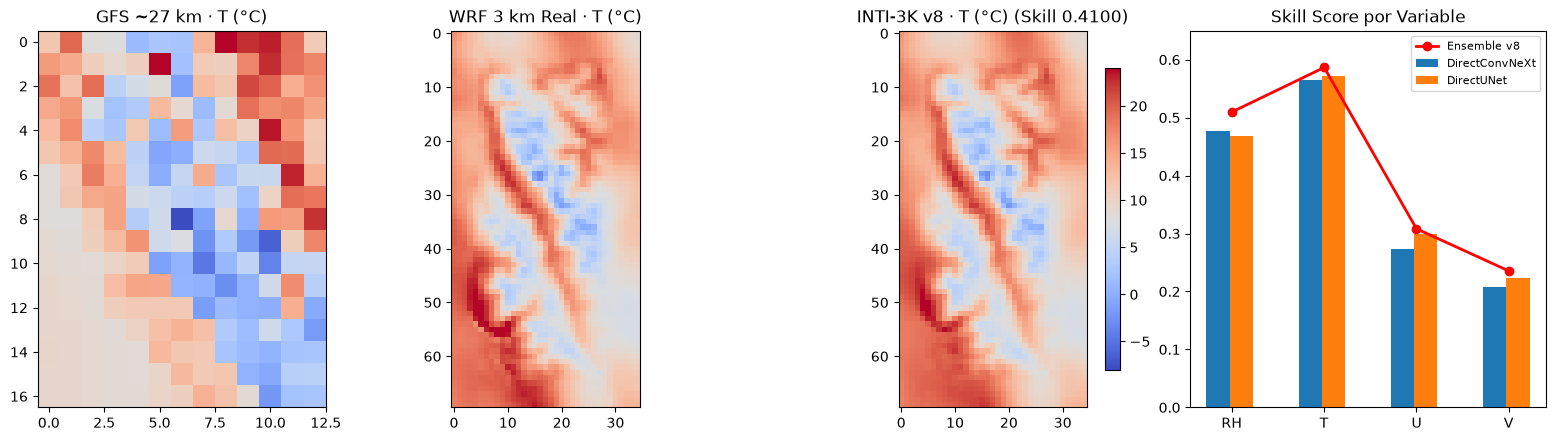

In [5]:
def update_ema(ema_model, model, decay=0.992):
    with torch.no_grad():
        for pe, p in zip(ema_model.parameters(), model.parameters()):
            pe.data.mul_(decay).add_(p.data, alpha=1.0 - decay)

def predict_v8(net, Wn, Mn, Sn, Gn, Tn, h_all, bs=128):
    net.eval()
    preds = []
    with torch.no_grad():
        for s in range(0, len(Wn), bs):
            xb = torch.tensor(Wn[s:s+bs], dtype=torch.float32, device=device)
            mb = torch.tensor(Mn[s:s+bs], dtype=torch.float32, device=device)
            sb = torch.tensor(Sn[s:s+bs], dtype=torch.float32, device=device)
            gb = torch.tensor(Gn[s:s+bs], dtype=torch.float32, device=device)
            tb = torch.tensor(Tn[s:s+bs], dtype=torch.float32, device=device)
            hb = torch.tensor(h_all[s:s+bs], dtype=torch.long, device=device)
            y_hat = net(xb, mb, sb, gb, tb, hb).cpu().numpy()
            y_hat[..., 0] = np.clip(y_hat[..., 0], 0.0, 100.0)
            preds.append(y_hat)
    return np.concatenate(preds, axis=0)

def train_member(name, model, ctx, fit_mask, eval_mask=None, epochs=24, batch_size=32, lr=1.8e-3, weight_decay=1.5e-2, noise_std=0.045, seed=42):
    seed_everything(seed)
    model = model.to(device)
    ema_model = copy.deepcopy(model).eval()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    itr = np.where(fit_mask)[0]
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, total_steps=epochs * int(np.ceil(len(itr) / batch_size)), pct_start=0.15
    )

    Wn, Mn, Sn, Gn, Tn, sw = ctx["Wn"], ctx["Mn"], ctx["Sn"], ctx["Gn"], ctx["Tn"], ctx["sw"]
    clim_rmse_t = ctx["clim_rmse_t"]
    best_sc, best_state, best_ep = -1e9, None, epochs
    t0 = time.time()

    for ep in range(epochs):
        model.train()
        np.random.shuffle(itr)
        for s in range(0, len(itr), batch_size):
            b = itr[s:s+batch_size]
            xb = torch.tensor(Wn[b], dtype=torch.float32, device=device)
            mb = torch.tensor(Mn[b], dtype=torch.float32, device=device)
            sb = torch.tensor(Sn[b], dtype=torch.float32, device=device)
            gb = torch.tensor(Gn[b], dtype=torch.float32, device=device)
            tb = torch.tensor(Tn[b], dtype=torch.float32, device=device)
            hb = torch.tensor(h_tr[b], dtype=torch.long, device=device)
            wb = torch.tensor(sw[b], dtype=torch.float32, device=device)
            yb = torch.tensor(Ytr[b], dtype=torch.float32, device=device)
            if noise_std > 0:
                xb = xb + torch.randn_like(xb) * noise_std
                mb = mb + torch.randn_like(mb) * (noise_std * 0.5)
            y_pred = model(xb, mb, sb, gb, tb, hb)
            err_sq = ((y_pred - yb) ** 2).mean(dim=(1, 2))
            w_mse = (err_sq * wb[:, None]).sum(dim=0) / (wb.sum() + 1e-8)
            skill_loss = (torch.sqrt(w_mse + 1e-6) / clim_rmse_t).mean()
            optimizer.zero_grad()
            skill_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()
            scheduler.step()
            update_ema(ema_model, model, decay=0.992)

        if eval_mask is not None:
            vp_live = predict_v8(model, Wn[eval_mask], Mn[eval_mask], Sn[eval_mask], Gn[eval_mask], Tn[eval_mask], h_tr[eval_mask])
            sc_live, _, _ = evaluate_skill_score(vp_live, Ytr[eval_mask])
            sc_ema = -1e9
            if ep >= 5:
                vp_ema = predict_v8(ema_model, Wn[eval_mask], Mn[eval_mask], Sn[eval_mask], Gn[eval_mask], Tn[eval_mask], h_tr[eval_mask])
                sc_ema, _, _ = evaluate_skill_score(vp_ema, Ytr[eval_mask])
            sc_ep = max(sc_live, sc_ema)
            if sc_ep > best_sc:
                best_sc = sc_ep
                best_ep = ep + 1
                cand = ema_model if sc_ema >= sc_live else model
                best_state = {k: v.detach().cpu().clone() for k, v in cand.state_dict().items()}

    if eval_mask is None:
        best_state = {k: v.detach().cpu().clone() for k, v in ema_model.state_dict().items()}
        print(f"[Refit 100%] {name} completado en {time.time()-t0:.1f}s ({epochs} épocas, EMA)")
        oof = None
    else:
        model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
        oof = predict_v8(model, Wn[eval_mask], Mn[eval_mask], Sn[eval_mask], Gn[eval_mask], Tn[eval_mask], h_tr[eval_mask])
        sc_fin, _, sk_fin = evaluate_skill_score(oof, Ytr[eval_mask])
        print(f"[Fase A] {name:22s} · Ep={best_ep:02d} · Skill={sc_fin:.4f} · {sk_fin} · {time.time()-t0:.1f}s")

    del model, ema_model, optimizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()
    return best_state, oof, best_sc, best_ep

# --- FASE A: VALIDACIÓN TEMPORAL (>= 2024061600) ---
ctx_a = compute_norm_context(trn_mask)
specs_a = [
    ("DirectResConvNeXtV8", DirectResConvNeXtV8(grid_t, topo_t, ctx_a["lapse_delta_norm"], dem_delta_km_t, ctx_a["mu_x_t"], ctx_a["sd_x_t"], ctx_a["anom_sd_t"], w=84, dropout=0.15), 24, 1.8e-3, 1.5e-2, 0.045, 42),
    ("DirectResMultiScaleV8", DirectResMultiScaleV8(grid_t, topo_t, ctx_a["lapse_delta_norm"], dem_delta_km_t, ctx_a["mu_x_t"], ctx_a["sd_x_t"], ctx_a["anom_sd_t"], w=96, dropout=0.18), 24, 1.6e-3, 1.8e-2, 0.050, 102),
    ("DirectResUNetV8", DirectResUNetV8(grid_t, topo_t, ctx_a["lapse_delta_norm"], dem_delta_km_t, ctx_a["mu_x_t"], ctx_a["sd_x_t"], ctx_a["anom_sd_t"], w=64, dropout=0.14), 24, 1.5e-3, 1.4e-2, 0.040, 203),
    ("DirectResFNOV8", DirectResFNOV8(grid_t, topo_t, ctx_a["lapse_delta_norm"], dem_delta_km_t, ctx_a["mu_x_t"], ctx_a["sd_x_t"], ctx_a["anom_sd_t"], w=32, dropout=0.18), 24, 1.8e-3, 2.5e-2, 0.050, 304),
]

oofs_a, opt_epochs, member_skills = [], [], []
lapse_first = None
for name, mod, eps, lr, wd, n_std, sd in specs_a:
    st_m, oof, sc_m, ep_m = train_member(name, mod, ctx_a, trn_mask, val_mask, epochs=eps, lr=lr, weight_decay=wd, noise_std=n_std, seed=sd)
    if lapse_first is None:
        lapse_first = (
            st_m["anchor.lapse_rate_h"].squeeze().numpy(),
            st_m["anchor.rh_elev_h"].squeeze().numpy(),
        )
    oofs_a.append(oof)
    opt_epochs.append(max(14, min(ep_m, 22)))
    member_skills.append(evaluate_skill_score(oof, Ytr[val_mask])[2])

# Pesos regularizados en simplex (paso 0.05)
step = 0.05
n_steps = int(round(1.0 / step))
combos = [
    (i0 * step, i1 * step, i2 * step, (n_steps - i0 - i1 - i2) * step)
    for i0 in range(n_steps + 1)
    for i1 in range(n_steps + 1 - i0)
    for i2 in range(n_steps + 1 - i0 - i1)
]
W_grid = np.asarray(combos, dtype=np.float32)
reg_vec = 0.0015 * ((W_grid - 0.25) ** 2).sum(axis=1)

BLEND_WEIGHTS = np.zeros((4, 4), dtype=np.float32)
oof_ens_a = np.empty_like(oofs_a[0])
for v_idx in range(4):
    M = np.stack([o[..., v_idx].reshape(-1) for o in oofs_a], axis=0)
    E = M - Ytr[val_mask, ..., v_idx].reshape(1, -1)
    C_err = (E @ E.T) / float(E.shape[1])
    rmses = np.sqrt(np.maximum(np.einsum("ci,ij,cj->c", W_grid, C_err, W_grid), 1e-12))
    best_wv = W_grid[int(np.argmin(rmses / float(clim_rmse_val[v_idx]) + reg_vec))]
    BLEND_WEIGHTS[:, v_idx] = best_wv
    oof_ens_a[..., v_idx] = sum(float(best_wv[k]) * oofs_a[k][..., v_idx] for k in range(4))

sc_val_a, rmse_val_a, skill_val_a = evaluate_skill_score(oof_ens_a, Ytr[val_mask])
print("=" * 84)
print(f"FASE A (HOLDOUT 16-30 JUN) -> ENSEMBLE v8 SKILL SCORE: {sc_val_a:.4f}")
print(f"  Skill por variable : {skill_val_a}")
print(f"  RMSE por variable  : {rmse_val_a}")
print(f"  Épocas óptimas Refit: {opt_epochs}")
print("  Pesos blend (Conv, MS, UNet, FNO) por [RH, T, U, V]:")
print(BLEND_WEIGHTS)
lr_h, rh_h = lapse_first
print(f"  Lapse-Rate T (K/km) 00UTC={lr_h[0]:.2f}, 06UTC={lr_h[6]:.2f}, 12UTC={lr_h[12]:.2f}, 18UTC={lr_h[18]:.2f}")
print(f"  Lapse-Rate RH (%/km) 00UTC={rh_h[0]:.2f}, 12UTC={rh_h[12]:.2f}, 18UTC={rh_h[18]:.2f}")
print("=" * 84)

# Visualización comparativa
sample_idx = min(18, len(oof_ens_a) - 1)
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.3), constrained_layout=True)
axes[0].imshow(Xtr[val_mask][sample_idx, ..., 1] - 273.15, cmap="coolwarm")
axes[0].set_title("GFS ~27 km · T (°C)")
im1 = axes[1].imshow(np.flipud(Ytr[val_mask][sample_idx, ..., 1]) - 273.15, cmap="coolwarm", vmin=-8, vmax=24)
axes[1].set_title("WRF 3 km Real · T (°C)")
axes[2].imshow(np.flipud(oof_ens_a[sample_idx, ..., 1]) - 273.15, cmap="coolwarm", vmin=-8, vmax=24)
axes[2].set_title(f"INTI-3K v8 · T (°C) (Skill {sc_val_a:.4f})")
plt.colorbar(im1, ax=axes[2], shrink=0.8)
x_pos = np.arange(4)
axes[3].bar(x_pos - 0.15, [member_skills[0][v] for v in VARS], 0.25, label="DirectConvNeXt")
axes[3].bar(x_pos + 0.10, [member_skills[2][v] for v in VARS], 0.25, label="DirectUNet")
axes[3].plot(x_pos, [skill_val_a[v] for v in VARS], "ro-", linewidth=2, label="Ensemble v8")
axes[3].set_xticks(x_pos); axes[3].set_xticklabels(VARS)
axes[3].set_ylim(0, 0.65); axes[3].set_title("Skill Score por Variable")
axes[3].legend(fontsize=8)
plt.show()


In [6]:
print("Iniciando Fase B: Reentrenamiento final con 100% de la data oficial (2,935 horas Feb-Jun)...")
ctx_full = compute_norm_context(full_mask)

specs_full = [
    ("DirectResConvNeXtV8", DirectResConvNeXtV8(grid_t, topo_t, ctx_full["lapse_delta_norm"], dem_delta_km_t, ctx_full["mu_x_t"], ctx_full["sd_x_t"], ctx_full["anom_sd_t"], w=84, dropout=0.15), opt_epochs[0], 1.8e-3, 1.5e-2, 0.045, 42),
    ("DirectResMultiScaleV8", DirectResMultiScaleV8(grid_t, topo_t, ctx_full["lapse_delta_norm"], dem_delta_km_t, ctx_full["mu_x_t"], ctx_full["sd_x_t"], ctx_full["anom_sd_t"], w=96, dropout=0.18), opt_epochs[1], 1.6e-3, 1.8e-2, 0.050, 102),
    ("DirectResUNetV8", DirectResUNetV8(grid_t, topo_t, ctx_full["lapse_delta_norm"], dem_delta_km_t, ctx_full["mu_x_t"], ctx_full["sd_x_t"], ctx_full["anom_sd_t"], w=64, dropout=0.14), opt_epochs[2], 1.5e-3, 1.4e-2, 0.040, 203),
    ("DirectResFNOV8", DirectResFNOV8(grid_t, topo_t, ctx_full["lapse_delta_norm"], dem_delta_km_t, ctx_full["mu_x_t"], ctx_full["sd_x_t"], ctx_full["anom_sd_t"], w=32, dropout=0.18), opt_epochs[3], 1.8e-3, 2.5e-2, 0.050, 304),
]

full_states = []
for name, mod, eps, lr, wd, n_std, sd in specs_full:
    st_dict, _, _, _ = train_member(name, mod, ctx_full, full_mask, eval_mask=None, epochs=eps, lr=lr, weight_decay=wd, noise_std=n_std, seed=sd)
    full_states.append(st_dict)

ensemble_v8 = EnsembleV8(
    grid=grid_t,
    topo_features=topo_t,
    lapse_delta_norm=ctx_full["lapse_delta_norm"],
    dem_delta_km=dem_delta_km_t,
    mu_x=ctx_full["mu_x_t"],
    sd_x=ctx_full["sd_x_t"],
    anom_sd=ctx_full["anom_sd_t"],
    blend_weights=BLEND_WEIGHTS,
).to(device)

ensemble_v8.m_conv.load_state_dict({k: v.to(device) for k, v in full_states[0].items()})
ensemble_v8.m_ms.load_state_dict({k: v.to(device) for k, v in full_states[1].items()})
ensemble_v8.m_unet.load_state_dict({k: v.to(device) for k, v in full_states[2].items()})
ensemble_v8.m_fno.load_state_dict({k: v.to(device) for k, v in full_states[3].items()})
ensemble_v8.eval()

# Benchmark inferencia 24h
W_te_n = ((W_te - ctx_full["mu_x"]) / ctx_full["sd_x"]).astype(np.float32)
M24_te_n = ((M24_te - ctx_full["mu_x"]) / ctx_full["sd_x"]).astype(np.float32)
S24_te_n = (S24_te / ctx_full["sd_x"]).astype(np.float32)
GRAD_te_n = ((GRAD_te - ctx_full["mu_grad"]) / ctx_full["sd_grad"]).astype(np.float32)
TD_te_n = ((TD_te - ctx_full["mu_td"]) / ctx_full["sd_td"]).astype(np.float32)

t_inf0 = time.time()
_ = predict_v8(ensemble_v8, W_te_n[:24], M24_te_n[:24], S24_te_n[:24], GRAD_te_n[:24], TD_te_n[:24], h_te[:24], bs=24)
inf_24h_ms = (time.time() - t_inf0) * 1000.0
n_params_total = sum(p.numel() for p in ensemble_v8.parameters())
print(f"EnsembleV8 unificado: {n_params_total:,} parámetros | Inferencia 24h: {inf_24h_ms:.1f} ms en {device.upper()}")


Iniciando Fase B: Reentrenamiento final con 100% de la data oficial (2,935 horas Feb-Jun)...


[Refit 100%] DirectResConvNeXtV8 completado en 244.2s (16 épocas, EMA)


[Refit 100%] DirectResMultiScaleV8 completado en 354.4s (19 épocas, EMA)


[Refit 100%] DirectResUNetV8 completado en 144.1s (14 épocas, EMA)


[Refit 100%] DirectResFNOV8 completado en 139.0s (14 épocas, EMA)


EnsembleV8 unificado: 5,594,404 parámetros | Inferencia 24h: 185.9 ms en CUDA


In [7]:
weights_path = MODELS_DIR / "modelo.pt"
torch.save({k: v.detach().cpu() for k, v in ensemble_v8.state_dict().items()}, weights_path)
print(f"Pesos limpios guardados en {weights_path} ({weights_path.stat().st_size / 1e6:.2f} MB)")

np.savez_compressed(
    MODELS_DIR / "norm_stats.npz",
    mu_x=ctx_full["mu_x"],
    sd_x=ctx_full["sd_x"],
    mu_td=np.array(ctx_full["mu_td"], dtype=np.float32),
    sd_td=np.array(ctx_full["sd_td"], dtype=np.float32),
    mu_grad=ctx_full["mu_grad"],
    sd_grad=ctx_full["sd_grad"],
    clim_trn=ctx_full["clim"],
    anom_sd=ctx_full["anom_sd"],
    clim_rmse_val=clim_rmse_val,
    val_rmse_per_var=np.array([rmse_val_a[v] for v in VARS], dtype=np.float32),
    val_skill_per_var=np.array([skill_val_a[v] for v in VARS], dtype=np.float32),
    blend_weights=BLEND_WEIGHTS,
    arch=np.array("ensemble_v8"),
    width=np.array(84),
    best_score=np.array(sc_val_a),
    exp_id=np.array("ensemble_v8_full_directres"),
)

test_preds = predict_v8(ensemble_v8, W_te_n, M24_te_n, S24_te_n, GRAD_te_n, TD_te_n, h_te)
sample = pd.read_csv(find("sample_submission.csv"))
pos = {k: i for i, k in enumerate(tte)}
parts = sample["id"].str.split("_", expand=True)
ti = parts[0].map(pos).values
r = parts[1].astype(int).values
c = parts[2].astype(int).values

sub = pd.DataFrame({"id": sample["id"]})
for k, v in enumerate(VARS):
    sub[v] = test_preds[ti, r, c, k].round(3)

sub_path = ROOT_DIR / "submission.csv"
sub.to_csv(sub_path, index=False)

assert sub.shape == sample.shape, f"Shape mismatch: {sub.shape} vs {sample.shape}"
assert list(sub.columns) == list(sample.columns)
assert int(sub.isna().sum().sum()) == 0, "NaNs detectados"
assert (sub["id"].values == sample["id"].values).all(), "IDs desalineados"

print(f"submission.csv verificado y guardado en {sub_path}: shape={sub.shape}")
for v in VARS:
    print(f"  [{v}] min={sub[v].min():.3f} | mean={sub[v].mean():.3f} | max={sub[v].max():.3f}")
sub.head()


Pesos limpios guardados en C:\Users\Acer\Desktop\Estudio\Proyectos\IA_PUCP\models\modelo.pt (23.11 MB)


submission.csv verificado y guardado en C:\Users\Acer\Desktop\Estudio\Proyectos\IA_PUCP\submission.csv: shape=(646800, 5)
  [RH] min=0.000 | mean=55.105 | max=100.000
  [T] min=264.106 | mean=281.994 | max=299.848
  [U] min=-14.530 | mean=-1.125 | max=15.937
  [V] min=-17.264 | mean=-0.580 | max=9.553


,id,RH,T,U,V
0,2024070200_00_00,96.920998,289.053986,-0.367,4.734
1,2024070200_00_01,95.430000,288.921997,0.077,4.030
2,2024070200_00_02,91.752998,289.019012,0.483,3.603
3,2024070200_00_03,87.260002,289.161987,0.478,3.044
4,2024070200_00_04,83.139000,289.446014,0.305,2.367
